# Fundamental diagram experiments
Scatter flow-density points against the fundamental diagram implied by the calibrated parameters, one panel per (segment, parameter window).
- Static calibration: `num_segments` panels.
- Dynamic calibration: `num_segments * total_timesteps / control_h` panels (rows = parameter windows, columns = segments).

In [2]:
# Find the repo root (the folder containing src/paths.py), put src/ on the import
# path, and run from the repo root so relative data/ and calibration/ paths resolve.
import os, sys
_root = os.path.abspath(os.getcwd())
while not os.path.exists(os.path.join(_root, "src", "paths.py")):
    _parent = os.path.dirname(_root)
    if _parent == _root:
        raise RuntimeError("Could not find src/paths.py above the working directory")
    _root = _parent
if os.path.join(_root, "src") not in sys.path:
    sys.path.insert(0, os.path.join(_root, "src"))
os.chdir(_root)

In [3]:
%load_ext autoreload
%autoreload 2

import math
import numpy as np
import matplotlib.pyplot as plt
from optimization_utils import smooth_inflow
from simulation_utils import run_metanet_sim
from param_loader import METANET_Params

## Load data

In [4]:
path_id = "i24/i24_11_30"
data_path = f"data/{path_id}"
calib_path = f"calibration/{path_id}"

lanes = np.load(f"{data_path}/lane_mapping.npy")
rho_hat = np.load(f"{data_path}/rho_hat.npy")   # total density (veh/km), includes boundary cells
q_hat = np.load(f"{data_path}/q_hat.npy")       # total flow (veh/h), includes boundary cells
rho_hat = np.where(rho_hat == 0.0, 1e-3, rho_hat)
q_hat = np.where(q_hat == 0.0, 1e-3, q_hat)
v_hat = q_hat / rho_hat

T = 10/3600
l = 0.4
num_timesteps = rho_hat.shape[0]
num_calibrated_segments = rho_hat.shape[1] - 2
seg_lanes = lanes[1:-1]

downstream_density = smooth_inflow(rho_hat[:, -1] / lanes[-1])
data_inflow = smooth_inflow(q_hat[:, 0])
init_traffic_state = (rho_hat[0, 1:-1] / seg_lanes, v_hat[0, 1:-1], data_inflow[0], 0)
print(rho_hat.shape, num_calibrated_segments)

(360, 16) 14


## Load calibrations

In [5]:
control_h = 90
static_params = METANET_Params(f"{calib_path}/calibration_static/fixed_ramping",
                               num_segments=num_calibrated_segments).get_params()
dynamic_params = METANET_Params(f"{calib_path}/calibration_dynamic_smooth", control_h=control_h,
                                num_timesteps=num_timesteps,
                                num_segments=num_calibrated_segments).get_params()

## Flow-density states
Both helpers return per-lane `(rho, q, v)` arrays of shape `(num_timesteps, num_segments)` for the calibrated segments.

In [6]:
def observed_states(rho_hat, q_hat, lanes):
    """Per-lane density/flow/speed of the calibrated segments (boundary cells dropped)."""
    seg_lanes = np.asarray(lanes)[1:-1]
    rho = rho_hat[:, 1:-1] / seg_lanes
    q = q_hat[:, 1:-1] / seg_lanes
    return rho, q, q / rho


def model_states(params, T=T, l=l, init_traffic_state=init_traffic_state, data_inflow=data_inflow,
                 downstream_density=downstream_density, seg_lanes=seg_lanes):
    """Per-lane density/flow/speed from an open-loop METANET run with the calibrated params."""
    rho, v, _, _ = run_metanet_sim(T, l, init_traffic_state, data_inflow, downstream_density, params,
                                   vsl_speeds=None,
                                   lanes={i: seg_lanes[i] for i in range(len(seg_lanes))},
                                   plotting=True, real_data=True)
    rho, v = rho[:-1], v[:-1]   # drop the final state so the length matches the data
    return rho, rho * v, v

## Plotting function

In [7]:
def fd_curve(rho, v_free, p_crit, a):
    """Per-lane METANET fundamental diagram q = rho * V(rho)."""
    return rho * v_free * np.exp(-(rho / p_crit) ** a / a)


def _param_at(params, key, t, i):
    p = np.asarray(params[key])
    return float(p[t, i]) if p.ndim == 2 else float(p.reshape(-1)[i])


def plot_fd_panels(params, rho, q, v=None, control_h=None, segments=None, windows=None,
                   ncols=7, rho_max=80, q_max=None, vmin=0, vmax=120,
                   cmap="RdYlGn", panel_size=(2.8, 2.4), s=8, title=None, colorbar=True,
                   save_path=None):
    """Scatter flow-density points against the calibrated FD in one panel per (window, segment).

    params:    METANET param dict. Each key is (num_segments,) for a static calibration or
               (num_timesteps, num_segments) for a dynamic one (as from METANET_Params).
    rho, q, v: per-lane arrays of shape (num_timesteps, num_segments), e.g. from
               observed_states(...) or model_states(...). Points are colored by v (q/rho if None).
    control_h: None for static (one window covering all timesteps), else the number of timesteps
               each parameter set is held for. Panels are then num_windows x num_segments.
    segments, windows: optional index subsets to plot.
    """
    num_timesteps, num_segments = rho.shape
    if v is None:
        v = q / np.maximum(rho, 1e-6)
    segments = list(range(num_segments)) if segments is None else list(segments)
    dynamic = control_h is not None
    H = control_h if dynamic else num_timesteps
    num_windows = math.ceil(num_timesteps / H)
    windows = list(range(num_windows)) if windows is None else list(windows)

    panels = [(w, i) for w in windows for i in segments]
    if dynamic:   # one row per parameter window, one column per segment
        nrows, ncols = len(windows), len(segments)
    else:
        ncols = min(ncols, len(panels))
        nrows = math.ceil(len(panels) / ncols)

    fig, axes = plt.subplots(nrows, ncols, sharex=True, sharey=True, squeeze=False, layout="constrained",
                             figsize=(panel_size[0] * ncols, panel_size[1] * nrows))
    rho_grid = np.linspace(0, rho_max, 400)
    max_capacity = 0.0

    for k, (w, i) in enumerate(panels):
        ax = axes.flat[k]
        t0, t1 = w * H, min((w + 1) * H, num_timesteps)
        v_free, p_crit, a = (_param_at(params, key, t0, i) for key in ("v_free", "p_crit", "a"))
        q_fd = fd_curve(rho_grid, v_free, p_crit, a)
        capacity = q_fd.max()
        max_capacity = max(max_capacity, capacity)

        sc = ax.scatter(rho[t0:t1, i], q[t0:t1, i], c=v[t0:t1, i], cmap=cmap, vmin=vmin, vmax=vmax, s=s)
        ax.plot(rho_grid, q_fd, color="k", lw=1.5)
        ax.axhline(capacity, color="k", ls="--", lw=1)
        label = f"S{i}  W{w}" if dynamic else f"S{i}"
        ax.set_title(label, fontsize=9)
        ax.set_xlim(0, rho_max)

    if q_max is None:   # fit the points and FD peaks, but don't let one degenerate FD squash every panel
        q_data = np.nanmax(q[:, segments])
        q_max = 1.1 * max(q_data, min(max_capacity, 1.5 * q_data))
    axes.flat[0].set_ylim(0, q_max)
    for ax in axes.flat[len(panels):]:
        ax.set_visible(False)

    fig.supxlabel(r"$\rho$ (veh/km/lane)")
    fig.supylabel("q (veh/h/lane)")
    if title is not None:
        fig.suptitle(title)
    if colorbar:
        fig.colorbar(sc, ax=axes.ravel().tolist(), label="v (km/h)", fraction=0.015, pad=0.005)
    if save_path is not None:
        os.makedirs(os.path.dirname(save_path) or ".", exist_ok=True)
        fig.savefig(save_path, bbox_inches="tight")
    plt.show()
    return fig, axes

## Static calibration

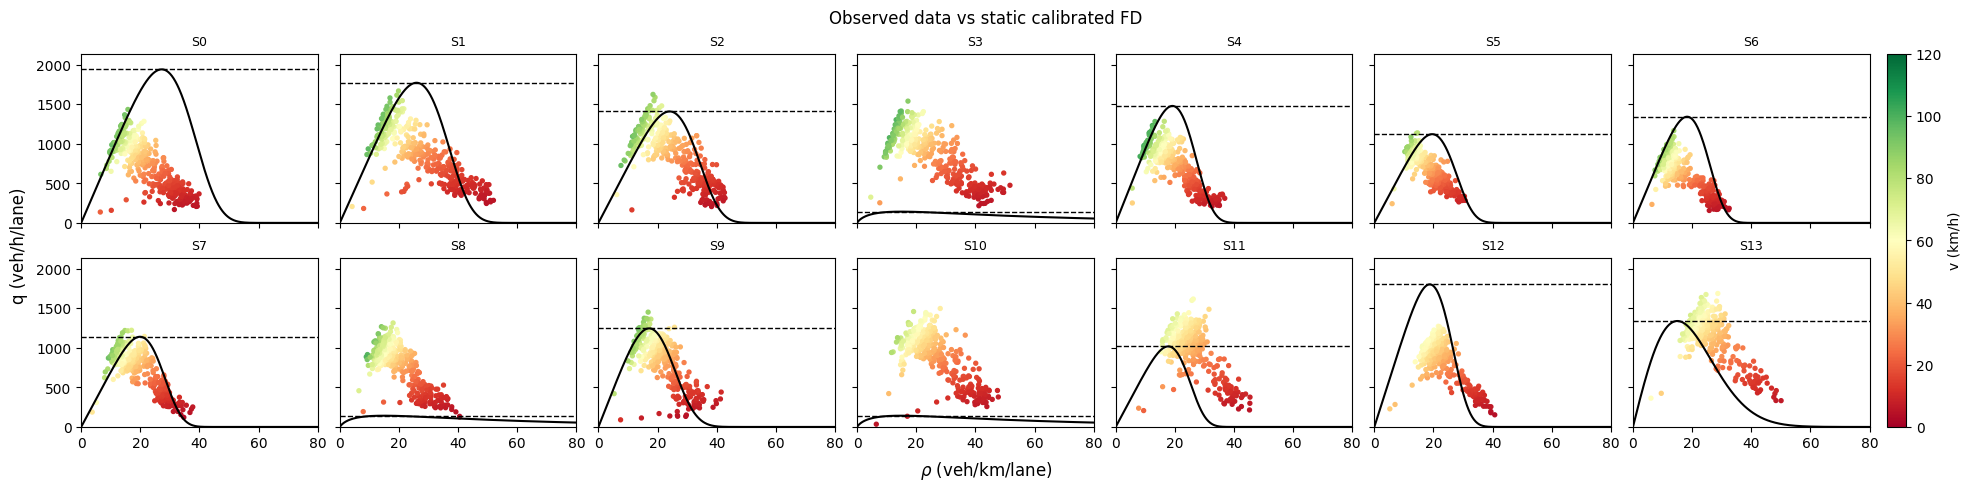

In [8]:
obs = observed_states(rho_hat, q_hat, lanes)
plot_fd_panels(static_params, *obs, title="Observed data vs static calibrated FD");

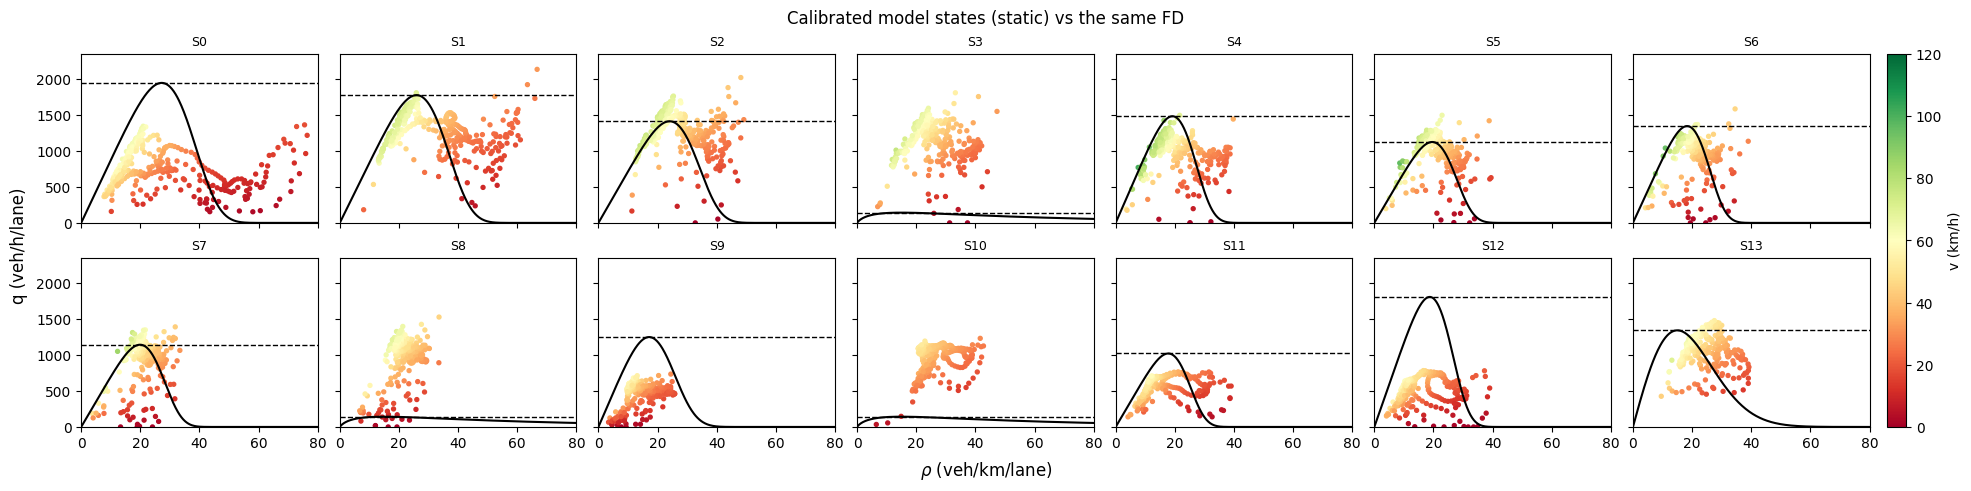

In [9]:
static_sim = model_states(static_params)
plot_fd_panels(static_params, *static_sim, title="Calibrated model states (static) vs the same FD");

## Dynamic calibration
Rows are parameter windows of `control_h` timesteps; columns are segments. Pass `segments=` / `windows=` to plot a subset (useful for short horizons).

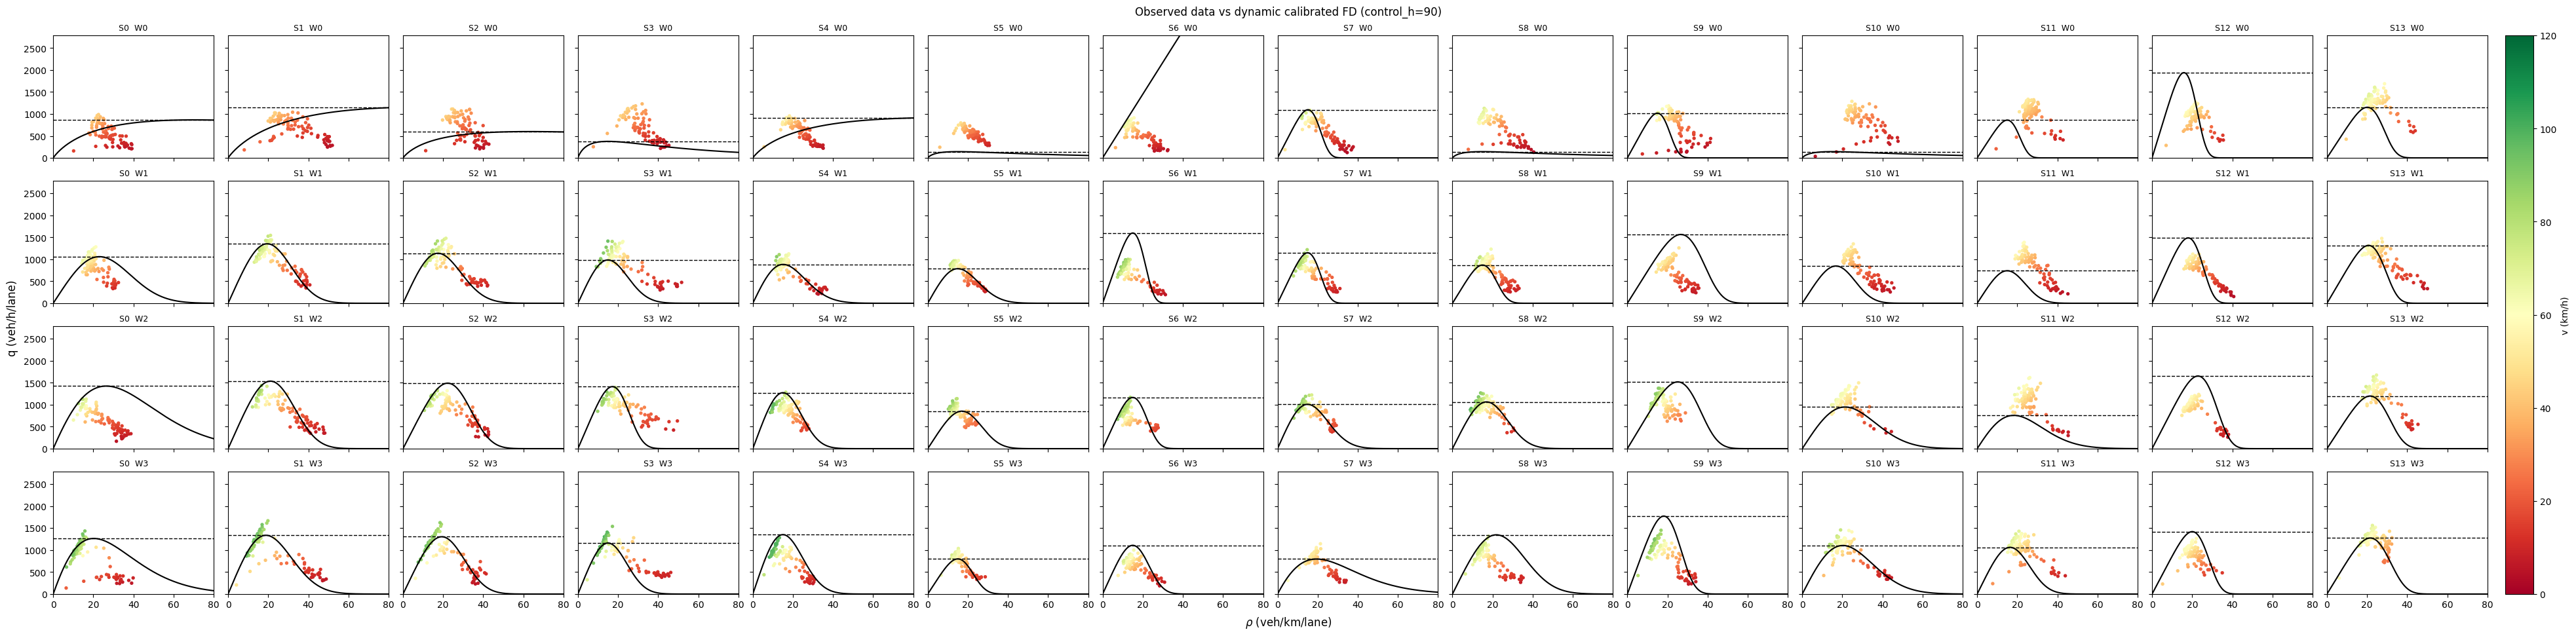

In [10]:
plot_fd_panels(dynamic_params, *obs, control_h=control_h,
               title=f"Observed data vs dynamic calibrated FD (control_h={control_h})");

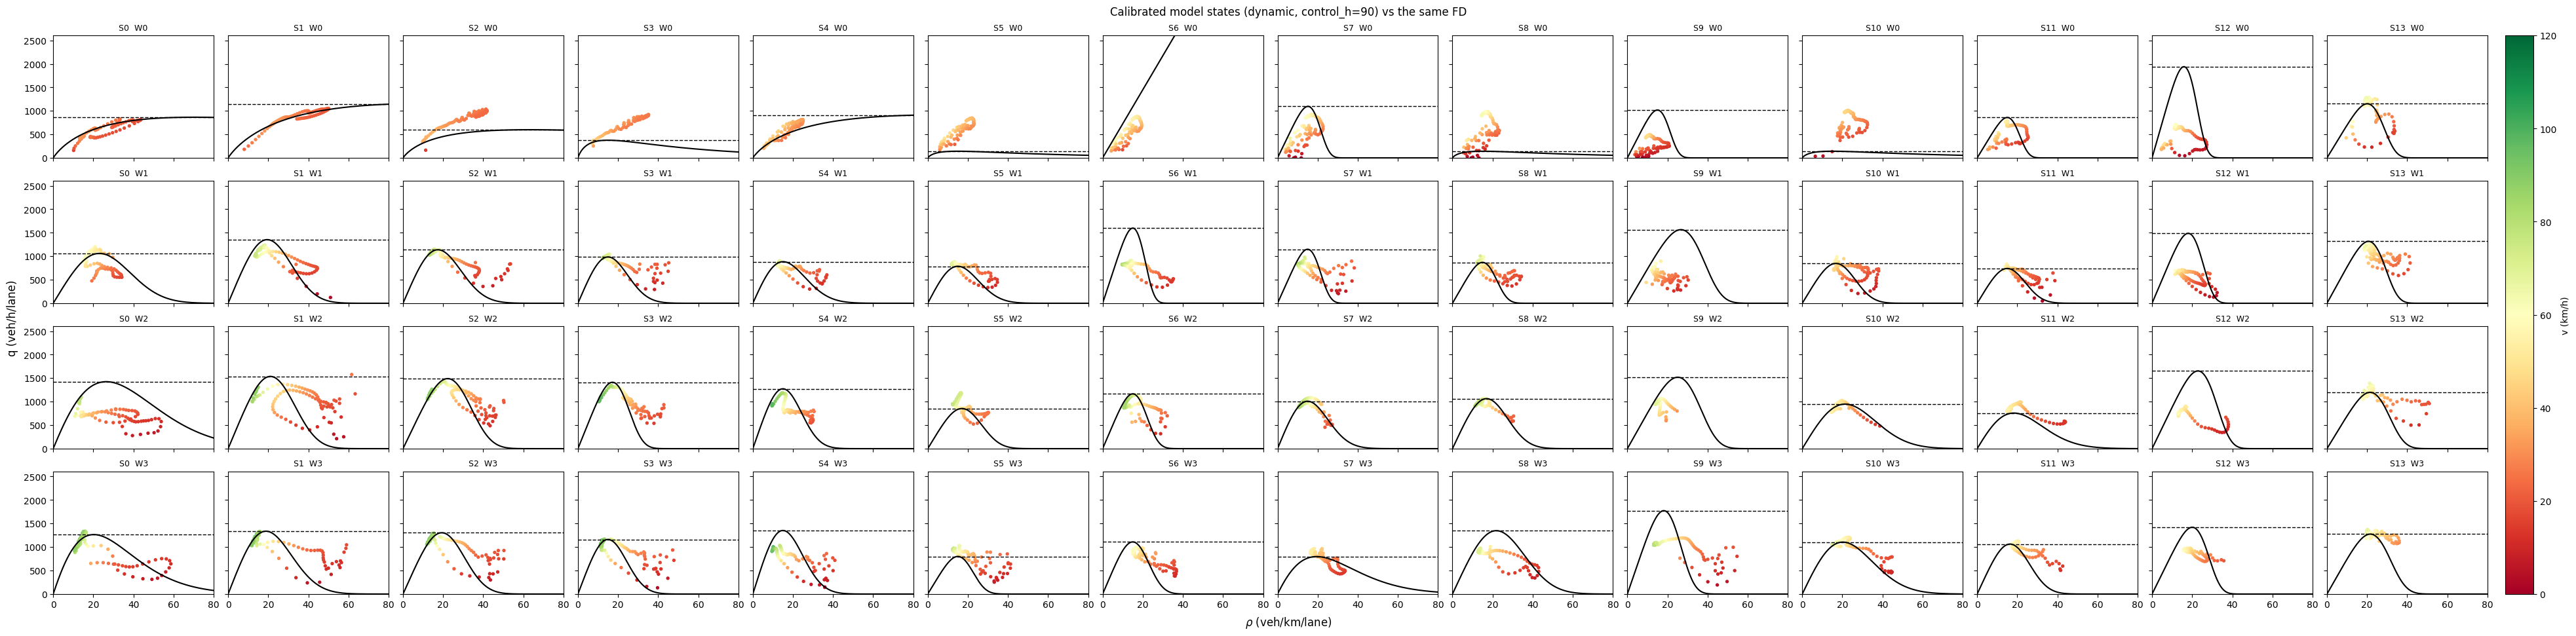

In [11]:
dynamic_sim = model_states(dynamic_params)
plot_fd_panels(dynamic_params, *dynamic_sim, control_h=control_h,
               title=f"Calibrated model states (dynamic, control_h={control_h}) vs the same FD");

## Rolling FD fit
For each segment, fit an FD to the observed per-lane data in the window `[s, s + H)`, then slide the start by `k` timesteps until the window reaches the end of the day. Each fit uses `fit_fd1` (least squares on q, solved with IPOPT).

In [12]:
import logging
from optimization_utils import fit_fd1

logging.getLogger("pyomo.core").setLevel(logging.ERROR)


def rolling_fd_fit(rho, q, H, k, segments=None):
    """Fit an FD to each sliding window [s, s + H), s = 0, k, 2k, ..., for each segment.

    rho, q: per-lane arrays of shape (num_timesteps, num_segments).
    Returns (starts, fits) where fits[key] has shape (num_windows, len(segments)) for
    key in ("v_free", "p_crit", "a").
    """
    num_timesteps, num_segments = rho.shape
    segments = list(range(num_segments)) if segments is None else list(segments)
    starts = np.arange(0, num_timesteps - H + 1, k)
    fits = {key: np.full((len(starts), len(segments)), np.nan) for key in ("v_free", "p_crit", "a")}
    for j, i in enumerate(segments):
        for w, s in enumerate(starts):
            p = fit_fd1(rho[s:s + H, i], q[s:s + H, i], plot=False)
            fits["v_free"][w, j], fits["p_crit"][w, j], fits["a"][w, j] = p["V_free"], p["rho_crit"], p["a"]
    return starts, fits

In [16]:
steps_per_min = int(round(1 / (T * 60)))   # 6 timesteps per minute at T = 10 s
H_fit = 15 * steps_per_min                  # 20 min window
k_fit = 1 * steps_per_min                   # 1 min shift

rho_obs, q_obs, _ = obs
fit_starts, rolling_fits = rolling_fd_fit(rho_obs, q_obs, H_fit, k_fit)
print(f"{len(fit_starts)} windows x {num_calibrated_segments} segments")

46 windows x 14 segments


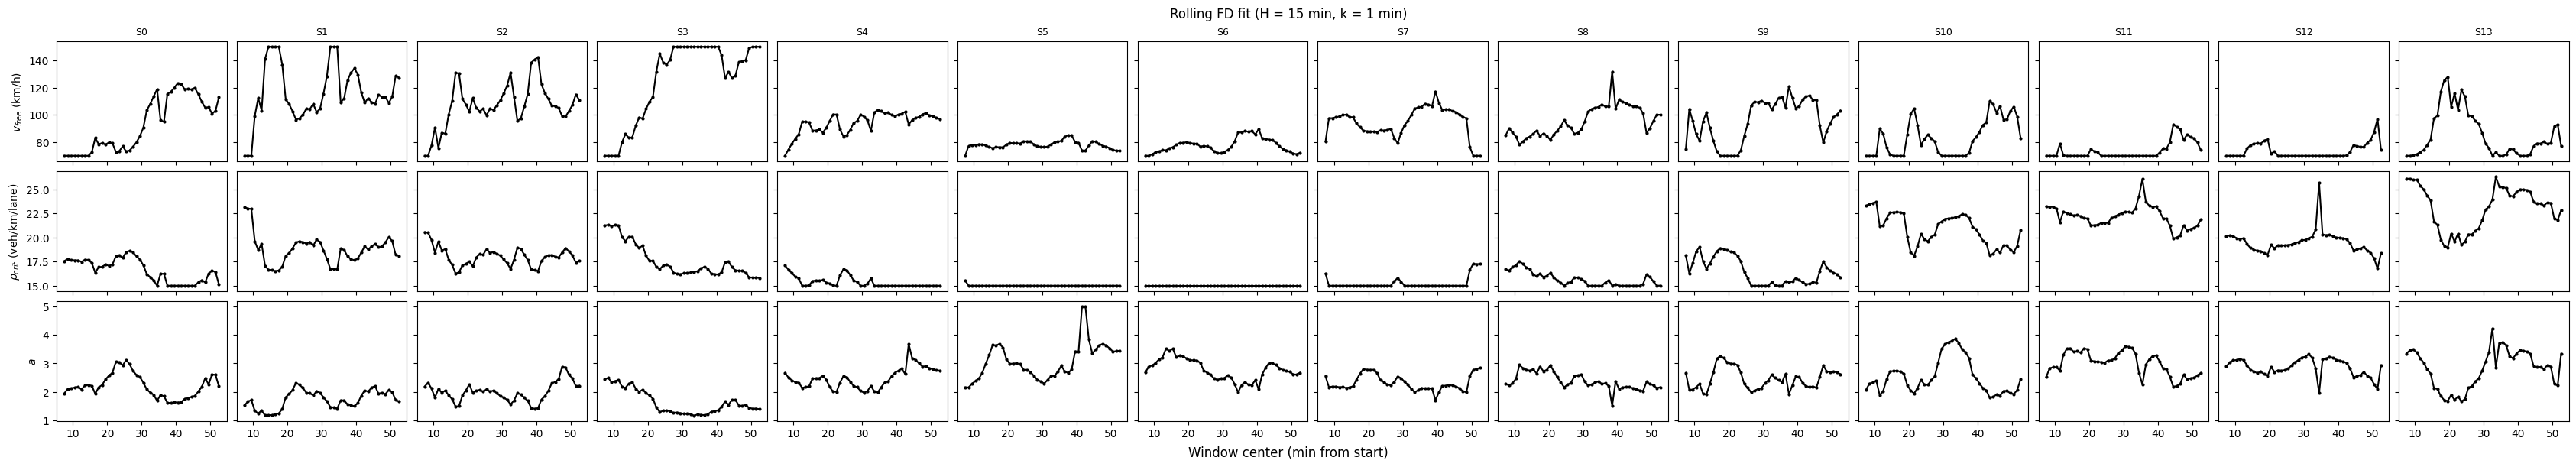

In [17]:
def plot_rolling_fd_params(starts, fits, H, k, segments=None, ref_params=None, ref_label="Static calibration",
                           panel_size=(2.4, 2.0), title=None, save_path=None):
    """One row per FD parameter, one column per segment; x is the window center (min from start).

    ref_params: optional METANET param dict (static) drawn as a dashed reference line.
    """
    keys = [("v_free", r"$v_{free}$ (km/h)"), ("p_crit", r"$\rho_{crit}$ (veh/km/lane)"), ("a", r"$a$")]
    num_segments = fits["v_free"].shape[1]
    segments = list(range(num_segments)) if segments is None else list(segments)
    t_center = (starts + H / 2) * T * 60

    fig, axes = plt.subplots(len(keys), num_segments, sharex=True, sharey="row", squeeze=False,
                             layout="constrained",
                             figsize=(panel_size[0] * num_segments, panel_size[1] * len(keys)))
    for r, (key, ylabel) in enumerate(keys):
        for j, i in enumerate(segments):
            ax = axes[r, j]
            ax.plot(t_center, fits[key][:, j], color="k", lw=1.5, marker="o", ms=2)
            if ref_params is not None:
                ax.axhline(_param_at(ref_params, key, 0, i), color="tab:red", ls="--", lw=1, label=ref_label)
            if r == 0:
                ax.set_title(f"S{i}", fontsize=9)
        axes[r, 0].set_ylabel(ylabel)
    if ref_params is not None:
        fig.legend(*axes[0, 0].get_legend_handles_labels(), loc="outside upper right", fontsize=9)
    fig.supxlabel("Window center (min from start)")
    fig.suptitle(title if title is not None else
                 f"Rolling FD fit (H = {H * T * 60:g} min, k = {k * T * 60:g} min)")
    if save_path is not None:
        os.makedirs(os.path.dirname(save_path) or ".", exist_ok=True)
        fig.savefig(save_path, bbox_inches="tight")
    plt.show()
    return fig, axes


plot_rolling_fd_params(fit_starts, rolling_fits, H_fit, k_fit, ref_params=None);

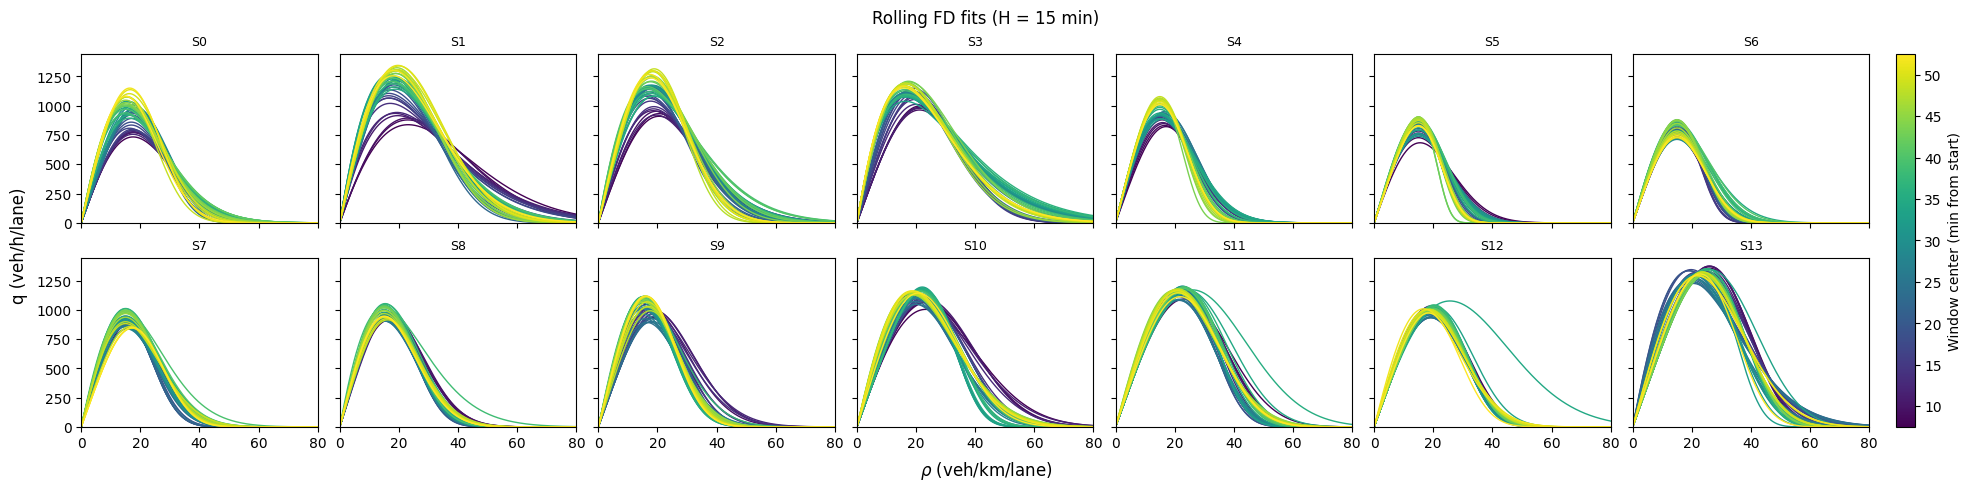

In [18]:
def plot_rolling_fd_curves(starts, fits, H, segments=None, ncols=7, rho_max=80, q_max=None,
                           cmap="viridis", panel_size=(2.8, 2.4), title=None, save_path=None):
    """One panel per segment with every rolling-window FD overlaid, colored by window center time."""
    num_segments = fits["v_free"].shape[1]
    segments = list(range(num_segments)) if segments is None else list(segments)
    t_center = (starts + H / 2) * T * 60
    norm = plt.Normalize(t_center.min(), t_center.max())
    colors = plt.get_cmap(cmap)(norm(t_center))
    rho_grid = np.linspace(0, rho_max, 400)

    ncols = min(ncols, len(segments))
    nrows = math.ceil(len(segments) / ncols)
    fig, axes = plt.subplots(nrows, ncols, sharex=True, sharey=True, squeeze=False, layout="constrained",
                             figsize=(panel_size[0] * ncols, panel_size[1] * nrows))
    max_capacity = 0.0
    for k, j in enumerate(segments):
        ax = axes.flat[k]
        for w in range(len(starts)):
            q_fd = fd_curve(rho_grid, fits["v_free"][w, j], fits["p_crit"][w, j], fits["a"][w, j])
            max_capacity = max(max_capacity, q_fd.max())
            ax.plot(rho_grid, q_fd, color=colors[w], lw=1)
        ax.set_title(f"S{j}", fontsize=9)
        ax.set_xlim(0, rho_max)
    axes.flat[0].set_ylim(0, 1.05 * max_capacity if q_max is None else q_max)
    for ax in axes.flat[len(segments):]:
        ax.set_visible(False)

    fig.supxlabel(r"$\rho$ (veh/km/lane)")
    fig.supylabel("q (veh/h/lane)")
    fig.suptitle(title if title is not None else f"Rolling FD fits (H = {H * T * 60:g} min)")
    fig.colorbar(plt.cm.ScalarMappable(norm=norm, cmap=cmap), ax=axes.ravel().tolist(),
                 label="Window center (min from start)", fraction=0.015, pad=0.01)
    if save_path is not None:
        os.makedirs(os.path.dirname(save_path) or ".", exist_ok=True)
        fig.savefig(save_path, bbox_inches="tight")
    plt.show()
    return fig, axes


plot_rolling_fd_curves(fit_starts, rolling_fits, H_fit);